# Secure Aggregation — testes isolados

Protocolo em `protocol.py`. Dados: logits de `A_AE_CNN__MobileNetV2/2031` (3 rondas × 22 clientes × 32 âncoras × 2 classes).

In [1]:
import numpy as np
import pandas as pd
import protocol as sa

## 1. Verificação do protocolo

In [2]:
def check(nome, ok):
    print(('OK    ' if ok else 'FALHA ') + nome)

# troca de chaves: valores de teste do RFC 7748 (secção 6.1)
alice = bytes.fromhex('77076d0a7318a57d3c16c17251b26645df4c2f87ebc0992ab177fba51db92c2a')
bob   = bytes.fromhex('5dab087e624a8a4b79e17f8b83800ee66f3bb1292618b6fd1c2f8b27ff88e0eb')
A, B = sa.x25519(alice, sa.BASE), sa.x25519(bob, sa.BASE)
check('X25519: chave pública da Alice', A.hex() == '8520f0098930a754748b7ddcb43ef75a0dbf3a0d26381af4eba4a98eaa9b4e6a')
check('X25519: segredo partilhado', sa.x25519(alice, B) == sa.x25519(bob, A) ==
      bytes.fromhex('4a5d9d5ba4ce2de1728e3bf480350f25e07e21c947d19e3376f09b3c1e161742'))

# Shamir: t pedaços recuperam o segredo, t-1 não
p = sa.share(12345, 3, [1, 2, 3, 4, 5])
check('Shamir: 3 pedaços recuperam o segredo', sa.reconstruct({k: p[k] for k in [1, 3, 5]}) == 12345)
check('Shamir: 2 pedaços não recuperam', sa.reconstruct({k: p[k] for k in [1, 3]}) != 12345)

# cifragem: decifra e deteta alterações
key = bytes(32); box = sa.seal(key, b'pedaco')
check('Cifragem: decifra', sa.unseal(key, box) == b'pedaco')
try:
    sa.unseal(key, box[:-1] + bytes([box[-1] ^ 1])); check('Cifragem: deteta alteração', False)
except ValueError:
    check('Cifragem: deteta alteração', True)

# soma segura: exata, com e sem desistências; recusa abaixo de t
rng = np.random.default_rng(0)
X = {u: rng.integers(0, 2**20, 64).astype(np.uint64) for u in range(1, 11)}
for dm, du in [((), ()), ((2, 7), ()), ((2, 7), (1,))]:
    tot, rep = sa.secure_sum(X, t=6, drop_masked=dm, drop_unmask=du)
    check(f'Soma exata (desistem antes de enviar {dm}, antes de desmascarar {du})',
          np.array_equal(tot, sum(X[u] for u in rep['survivor_ids']) % sa.MOD))
try:
    sa.secure_sum(X, t=9, drop_masked=(1, 2)); check('Recusa com menos de t clientes', False)
except RuntimeError:
    check('Recusa com menos de t clientes', True)

OK    X25519: chave pública da Alice
OK    X25519: segredo partilhado
OK    Shamir: 3 pedaços recuperam o segredo
OK    Shamir: 2 pedaços não recuperam
OK    Cifragem: decifra
OK    Cifragem: deteta alteração


OK    Soma exata (desistem antes de enviar (), antes de desmascarar ())


OK    Soma exata (desistem antes de enviar (2, 7), antes de desmascarar ())


OK    Soma exata (desistem antes de enviar (2, 7), antes de desmascarar (1,))


OK    Recusa com menos de t clientes


## 2. O que o servidor vê

In [3]:
exemplo = {u: np.array([10*u, 1, 2], dtype=np.uint64) for u in range(1, 6)}
total, rep = sa.secure_sum(exemplo, t=3)
pd.DataFrame({'valor real': {u: v.tolist() for u, v in exemplo.items()},
              'recebido pelo servidor': {u: v.tolist() for u, v in rep['server_view'].items()}})

,valor real,recebido pelo servidor
1,"[10, 1, 2]","[2296236658, 1942535668, 1387069506]"
2,"[20, 1, 2]","[338632270, 939162237, 3626786308]"
3,"[30, 1, 2]","[2833124679, 225020586, 2021791133]"
4,"[40, 1, 2]","[1532536043, 3586873273, 2383949983]"
5,"[50, 1, 2]","[1034121065, 2138472938, 1003844134]"


In [4]:
print('soma pela SA:', total.tolist(), '| soma verdadeira:', sum(exemplo.values()).tolist())

soma pela SA: [150, 5, 10] | soma verdadeira: [150, 5, 10]


## 3. Dados

In [5]:
rounds = sa.load_rounds()
ids = rounds[0]['client_ids']
print(rounds[0]['logits'].shape, pd.Series([sa.origin(c) for c in ids]).value_counts().to_dict())
for r in rounds:
    erro = np.abs(sa.plain_consensus(sa.softmax(r['logits']), r['client_ids']) - r['consensus']).max()
    print(f"ronda {r['round']}: referência sem SA vs consenso guardado = {erro:.1e}")

(22, 32, 2) {'icentia11k': 16, 'physionet2017': 6}
ronda 1: referência sem SA vs consenso guardado = 3.6e-08
ronda 2: referência sem SA vs consenso guardado = 4.5e-08
ronda 3: referência sem SA vs consenso guardado = 3.8e-08


## 4. Sanidade: SA vs consenso original (t = 12, 16 bits)

In [6]:
rows = []
for r in rounds:
    probs = sa.softmax(r['logits'])
    for mode in ('per_origin', 'weighted'):
        c, rep, _ = sa.sa_consensus(probs, r['client_ids'], t=12, bits=16, mode=mode, planned_weights=r['weights'])
        rows.append(dict(ronda=r['round'], modo=mode, **sa.compare(c, r['consensus']),
                         tempo_s=round(rep['wall_seconds'], 2),
                         upload_kb=rep['upload_bytes_mean']/1024, upload_kb_sem_sa=rep['plain_upload_bytes']/1024))
pd.DataFrame(rows)

,ronda,modo,erro_max,mae,decisoes_alteradas,tempo_s,upload_kb,upload_kb_sem_sa
0,1,per_origin,0.000003,7.452133e-07,0,2.16,5.425781,0.50
1,1,weighted,0.000041,1.203874e-05,0,2.13,5.175781,0.25
2,2,per_origin,0.000002,7.570100e-07,0,2.07,5.425781,0.50
3,2,weighted,0.000037,1.065899e-05,0,2.16,5.175781,0.25
4,3,per_origin,0.000002,5.950763e-07,0,2.06,5.425781,0.50
5,3,weighted,0.000039,1.438812e-05,0,2.06,5.175781,0.25


## 5. Com 4 desistências (referência: sem SA, só com quem ficou)

In [7]:
r = rounds[0]; probs = sa.softmax(r['logits'])
drop = (1, 2, 17, 18)   # uids 1-16 Icentia, 17-22 PhysioNet
rows = []
for mode in ('per_origin', 'weighted'):
    c, rep, surv = sa.sa_consensus(probs, r['client_ids'], t=12, bits=16, mode=mode,
                                   drop_masked=drop, planned_weights=r['weights'])
    rows.append(dict(modo=mode, sobreviventes=rep['survivors'],
                     **sa.compare(c, sa.plain_consensus(probs, r['client_ids'], surv))))
pd.DataFrame(rows)

,modo,sobreviventes,erro_max,mae,decisoes_alteradas
0,per_origin,18,0.000003,0.000001,0
1,weighted,18,0.018252,0.009529,0


## 6. Experiências

In [8]:
import math
from pathlib import Path
import matplotlib.pyplot as plt

OUT = Path('results'); OUT.mkdir(exist_ok=True)
N = len(ids)
COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': .6,
                     'axes.edgecolor': '#52514e', 'axes.labelcolor': '#0b0b0b', 'font.size': 10,
                     'lines.linewidth': 2, 'lines.markersize': 6})

def save(fig, name):
    fig.tight_layout(); fig.savefig(OUT/f'{name}.png', dpi=200, bbox_inches='tight')

def p_success(n, t, d):
    # probabilidade de ficarem pelo menos t clientes quando cada um desiste com prob. d
    return sum(math.comb(n, k)*(1-d)**k*d**(n-k) for k in range(t, n+1))

### 6.1 Erro de quantização vs bits

In [9]:
BITS = [4, 6, 8, 10, 12, 14, 16, 20, 24, 27]
rows = []
for r in rounds:
    probs = sa.softmax(r['logits'])
    for mode in ('per_origin', 'weighted'):
        for b in BITS:
            c, rep, _ = sa.sa_consensus(probs, ids, t=12, bits=b, mode=mode, planned_weights=r['weights'])
            rows.append(dict(ronda=r['round'], modo=mode, bits=b, **sa.compare(c, r['consensus'])))
e_bits = pd.DataFrame(rows); e_bits.to_csv(OUT/'e1_bits.csv', index=False)
tab_bits = e_bits.groupby(['modo', 'bits']).agg(mae=('mae', 'mean'), erro_max=('erro_max', 'max'),
                                                decisoes_alteradas=('decisoes_alteradas', 'sum')).reset_index()
tab_bits.pivot(index='bits', columns='modo', values=['mae', 'erro_max', 'decisoes_alteradas'])

mae                    erro_max                \
modo    per_origin      weighted    per_origin      weighted   
bits                                                           
4     1.844649e-03  2.981771e-01  9.968857e-03  5.615433e-01   
6     6.193876e-04  1.331882e-02  2.329821e-03  3.815651e-02   
8     1.468450e-04  3.606339e-03  5.017122e-04  1.443404e-02   
10    3.532259e-05  8.307386e-04  1.166761e-04  2.720982e-03   
12    9.983222e-06  1.957893e-04  3.575285e-05  6.319284e-04   
14    2.635966e-06  5.172469e-05  1.170238e-05  1.630783e-04   
16    6.990999e-07  1.236195e-05  2.900759e-06  4.094839e-05   
20    4.707060e-08  8.186713e-07  1.490116e-07  2.622604e-06   
24    1.203605e-08  5.064067e-08  4.221996e-08  1.490116e-07   
27    1.159626e-08  1.334896e-08  4.516914e-08  4.470348e-08   

     decisoes_alteradas           
modo         per_origin weighted  
bits                              
4                   0.0      0.0  
6                   0.0      0.0  
8                   0.0      0.0  
10                  0.0      0.0  
12                  0.0      0.0  
14                  0.0      0.0  
16                  0.0      0.0  
20                  0.0      0.0  
24                  0.0      0.0  
27                  0.0      0.0

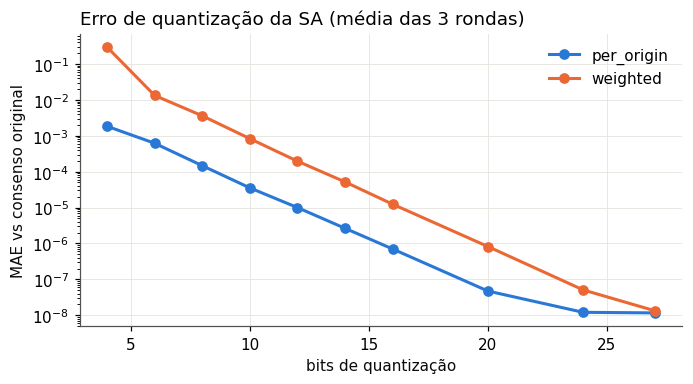

In [10]:
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for color, (mode, g) in zip(COLORS, tab_bits.groupby('modo')):
    ax.plot(g['bits'], g['mae'], marker='o', color=color, label=mode)
ax.set_yscale('log'); ax.set_xlabel('bits de quantização'); ax.set_ylabel('MAE vs consenso original')
ax.set_title('Erro de quantização da SA (média das 3 rondas)', loc='left')
ax.legend(frameon=False); save(fig, 'e1_bits')

### 6.2 Limiar: ronda com t − 1, t e t + 1 clientes (t = 12)

In [11]:
r = rounds[0]; probs = sa.softmax(r['logits']); rows = []
for survivors in (10, 11, 12, 13, 14):
    drop = tuple(range(1, N-survivors+1))
    try:
        c, rep, surv = sa.sa_consensus(probs, ids, t=12, bits=16, drop_masked=drop)
        rows.append(dict(sobreviventes=survivors, ronda_concluida=True, **sa.compare(c, sa.plain_consensus(probs, ids, surv))))
    except RuntimeError as e:
        rows.append(dict(sobreviventes=survivors, ronda_concluida=False, motivo=str(e)))
# desistências durante o desmascaramento: 18 enviam dados, k não respondem na etapa 3
for k in (0, 4, 6, 7):
    drop2 = tuple(range(1, 5)); drop3 = tuple(range(5, 5+k))
    try:
        c, rep, surv = sa.sa_consensus(probs, ids, t=12, bits=16, drop_masked=drop2, drop_unmask=drop3)
        rows.append(dict(sobreviventes=18, respondem_etapa3=18-k, ronda_concluida=True,
                         **sa.compare(c, sa.plain_consensus(probs, ids, surv))))
    except RuntimeError as e:
        rows.append(dict(sobreviventes=18, respondem_etapa3=18-k, ronda_concluida=False, motivo=str(e)))
e_limiar = pd.DataFrame(rows); e_limiar.to_csv(OUT/'e2_limiar.csv', index=False); e_limiar

,sobreviventes,ronda_concluida,motivo,erro_max,mae,decisoes_alteradas,respondem_etapa3
0,10,False,"Only 10 masked inputs, t=12",NaN,NaN,NaN,NaN
1,11,False,"Only 11 masked inputs, t=12",NaN,NaN,NaN,NaN
2,12,True,NaN,0.000003,9.143081e-07,0.0,NaN
3,13,True,NaN,0.000003,8.828678e-07,0.0,NaN
4,14,True,NaN,0.000003,7.995717e-07,0.0,NaN
5,18,True,NaN,0.000003,7.877689e-07,0.0,18.0
6,18,True,NaN,0.000003,7.877689e-07,0.0,14.0
7,18,True,NaN,0.000003,7.877689e-07,0.0,12.0
8,18,False,"Only 11 responses, t=12",NaN,NaN,NaN,11.0


### 6.3 Desistências × limiar t (per_origin, 16 bits, 10 repetições por célula)

In [12]:
T = [6, 8, 12, 15, 18]; D = [0, .1, .2, .3, .4, .5]; REPS = 10
rng = np.random.default_rng(2026); rows = []
for t in T:
    for d in D:
        for k in range(REPS):
            r = rounds[k % 3]; probs = sa.softmax(r['logits'])
            drop = tuple(u for u in range(1, N+1) if rng.random() < d)
            row = dict(t=t, desistencia=d, rep=k, desistiram=len(drop))
            try:
                c, rep, surv = sa.sa_consensus(probs, ids, t=t, bits=16, drop_masked=drop)
                row.update(ronda_concluida=True, tempo_s=rep['wall_seconds'], upload_bytes=rep['upload_bytes_mean'],
                           **sa.compare(c, sa.plain_consensus(probs, ids, surv)))
            except RuntimeError:
                row.update(ronda_concluida=False)
            rows.append(row)
e_drop = pd.DataFrame(rows); e_drop.to_csv(OUT/'e3_desistencias.csv', index=False)
tab_drop = e_drop.groupby(['t', 'desistencia']).agg(sucesso=('ronda_concluida', 'mean'), mae=('mae', 'mean'),
                                                    tempo_s=('tempo_s', 'mean')).reset_index()
tab_drop['sucesso_teorico'] = [p_success(N, t, d) for t, d in zip(tab_drop['t'], tab_drop['desistencia'])]
tab_drop.pivot(index='desistencia', columns='t', values='sucesso')

t,6,8,12,15,18
desistencia,,,,,
0.0,1.0,1.0,1.0,1.0,1.0
0.1,1.0,1.0,1.0,1.0,1.0
0.2,1.0,1.0,1.0,0.9,0.4
0.3,1.0,1.0,0.9,0.5,0.3
0.4,1.0,1.0,1.0,0.5,0.0
0.5,1.0,0.9,0.4,0.1,0.0


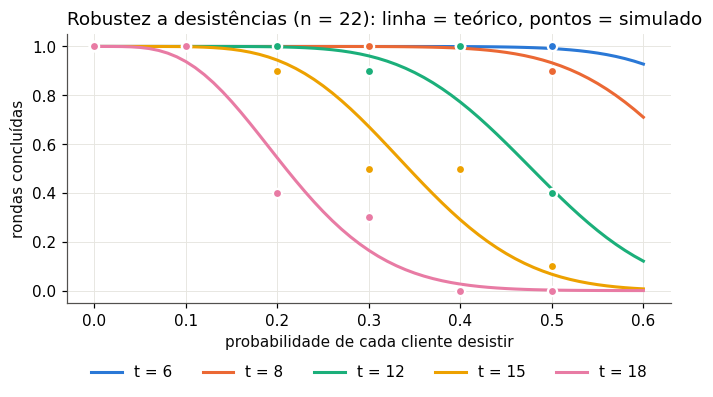

In [13]:
fig, ax = plt.subplots(figsize=(6.4, 3.8)); dd = np.linspace(0, .6, 61)
for color, t in zip(COLORS, T):
    g = tab_drop[tab_drop['t'] == t]
    ax.plot(dd, [p_success(N, t, d) for d in dd], color=color, label=f't = {t}')
    ax.plot(g['desistencia'], g['sucesso'], 'o', color=color, markeredgecolor='white', markeredgewidth=1.5)
ax.set_xlabel('probabilidade de cada cliente desistir'); ax.set_ylabel('rondas concluídas')
ax.set_title('Robustez a desistências (n = 22): linha = teórico, pontos = simulado', loc='left')
ax.legend(frameon=False, ncol=5, loc='upper center', bbox_to_anchor=(.5, -.18)); save(fig, 'e3_desistencias')

In [14]:
# compromisso do limiar: conluio tolerado (t - 1) vs desistências toleradas (n - t)
seg = pd.DataFrame(dict(t=T, conluio_tolerado=[t-1 for t in T], desistencias_toleradas=[N-t for t in T],
                        sucesso_20pct=[p_success(N, t, .2) for t in T], sucesso_30pct=[p_success(N, t, .3) for t in T]))
seg.to_csv(OUT/'e3_limiar_compromisso.csv', index=False); seg

,t,conluio_tolerado,desistencias_toleradas,sucesso_20pct,sucesso_30pct
0,6,5,16,1.000000,0.999994
1,8,7,14,0.999999,0.999754
2,12,11,10,0.998410,0.961255
3,15,14,7,0.943855,0.671251
4,18,17,4,0.542882,0.164549


### 6.4 per_origin vs weighted com desistências (t = 8)

In [15]:
rng = np.random.default_rng(7); rows = []
for d in (0, .1, .2, .3, .4):
    for k in range(5):
        r = rounds[k % 3]; probs = sa.softmax(r['logits'])
        drop = tuple(u for u in range(1, N+1) if rng.random() < d)
        for mode in ('per_origin', 'weighted'):
            c, rep, surv = sa.sa_consensus(probs, ids, t=8, bits=16, mode=mode, drop_masked=drop, planned_weights=r['weights'])
            rows.append(dict(desistencia=d, rep=k, modo=mode, **sa.compare(c, sa.plain_consensus(probs, ids, surv))))
e_modo = pd.DataFrame(rows); e_modo.to_csv(OUT/'e4_modo.csv', index=False)
tab_modo = e_modo.groupby(['modo', 'desistencia']).agg(mae=('mae', 'mean'), erro_max=('erro_max', 'max'),
                                                       decisoes_alteradas=('decisoes_alteradas', 'sum')).reset_index()
tab_modo.pivot(index='desistencia', columns='modo', values=['mae', 'decisoes_alteradas'])

mae           decisoes_alteradas         
modo           per_origin  weighted         per_origin weighted
desistencia                                                    
0.0          7.220306e-07  0.000012                0.0      0.0
0.1          7.597706e-07  0.003808                0.0      0.0
0.2          8.290404e-07  0.015252                0.0      0.0
0.3          9.109268e-07  0.010215                0.0      1.0
0.4          9.643762e-07  0.014992                0.0      0.0

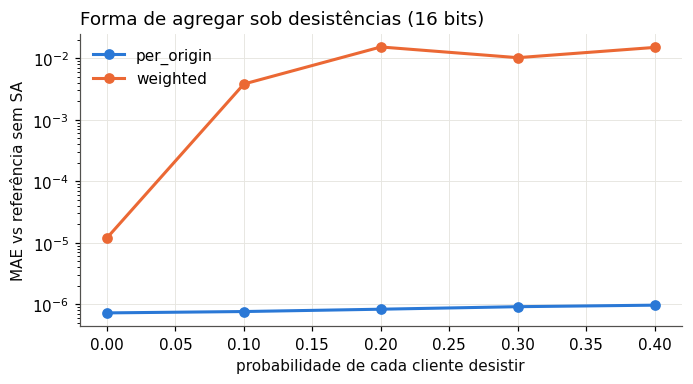

In [16]:
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for color, (mode, g) in zip(COLORS, tab_modo.groupby('modo')):
    ax.plot(g['desistencia'], g['mae'], marker='o', color=color, label=mode)
ax.set_yscale('log'); ax.set_xlabel('probabilidade de cada cliente desistir'); ax.set_ylabel('MAE vs referência sem SA')
ax.set_title('Forma de agregar sob desistências (16 bits)', loc='left'); ax.legend(frameon=False); save(fig, 'e4_modo')

### 6.5 Custo vs número de clientes (per_origin, 16 bits, t = ⌊n/2⌋ + 1)

In [17]:
ico = [i for i, c in enumerate(ids) if sa.origin(c) == 'icentia11k']; phy = [i for i, c in enumerate(ids) if sa.origin(c) == 'physionet2017']
rows = []
for n in (4, 8, 12, 16, 22):
    n_phy = max(1, round(n*len(phy)/N)); sel = ico[:n-n_phy] + phy[:n_phy]
    for k in range(3):
        r = rounds[k]; probs = sa.softmax(r['logits'])[sel]; sub = [ids[i] for i in sel]
        c, rep, _ = sa.sa_consensus(probs, sub, t=n//2+1, bits=16)
        rows.append(dict(n=n, t=n//2+1, tempo_total_s=rep['wall_seconds'], tempo_cliente_s=rep['client_seconds_mean'],
                         tempo_servidor_s=rep['server_seconds'], upload_kb=rep['upload_bytes_mean']/1024,
                         download_kb=rep['download_bytes_mean']/1024, upload_kb_sem_sa=rep['plain_upload_bytes']/1024))
e_custo = pd.DataFrame(rows).groupby(['n', 't']).mean().reset_index(); e_custo.to_csv(OUT/'e5_custo_clientes.csv', index=False)
e_custo.round(3)

,n,t,tempo_total_s,tempo_cliente_s,tempo_servidor_s,upload_kb,download_kb,upload_kb_sem_sa
0,4,3,0.057,0.014,0.002,1.312,0.695,0.5
1,8,5,0.289,0.033,0.022,2.227,1.617,0.5
2,12,7,0.656,0.050,0.053,3.141,2.539,0.5
3,16,9,1.300,0.074,0.108,4.055,3.461,0.5
4,22,12,2.273,0.095,0.186,5.426,4.844,0.5


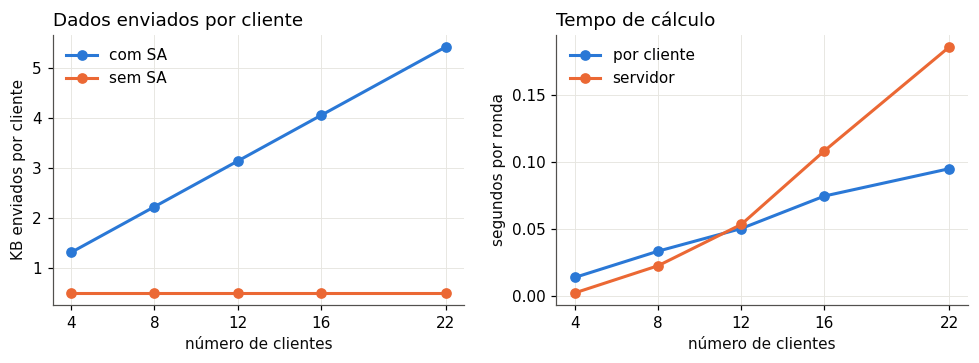

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].plot(e_custo['n'], e_custo['upload_kb'], marker='o', color=COLORS[0], label='com SA')
axes[0].plot(e_custo['n'], e_custo['upload_kb_sem_sa'], marker='o', color=COLORS[1], label='sem SA')
axes[0].set_xlabel('número de clientes'); axes[0].set_ylabel('KB enviados por cliente'); axes[0].legend(frameon=False)
axes[0].set_title('Dados enviados por cliente', loc='left')
axes[1].plot(e_custo['n'], e_custo['tempo_cliente_s'], marker='o', color=COLORS[0], label='por cliente')
axes[1].plot(e_custo['n'], e_custo['tempo_servidor_s'], marker='o', color=COLORS[1], label='servidor')
axes[1].set_xlabel('número de clientes'); axes[1].set_ylabel('segundos por ronda'); axes[1].legend(frameon=False)
axes[1].set_title('Tempo de cálculo', loc='left')
for a in axes: a.set_xticks(e_custo['n'])
save(fig, 'e5_custo_clientes')

### 6.6 Custo: soft labels vs FedAvg (n = 22, t = 12)

In [19]:
payloads = {'soft labels (weighted)': 64, 'soft labels (per_origin)': 128,
            'FedAvg CNN1D (professor Icentia)': 14954, 'FedAvg CNN1D (aluno global)': 20402,
            'FedAvg MobileNetV2 (professor PhysioNet)': 157938}
rows = []; rng = np.random.default_rng(0)
for name, L in payloads.items():
    X = {u: rng.integers(0, 2**16, L).astype(np.uint64) for u in range(1, N+1)}
    tot, rep = sa.secure_sum(X, t=12)
    assert np.array_equal(tot, sum(X.values()) % sa.MOD)
    rows.append(dict(contribuicao=name, valores=L, upload_kb_sem_sa=rep['plain_upload_bytes']/1024,
                     upload_kb_com_sa=rep['upload_bytes_mean']/1024, tempo_total_s=rep['wall_seconds']))
e_fedavg = pd.DataFrame(rows)
e_fedavg['acrescimo_sa_pct'] = 100*(e_fedavg['upload_kb_com_sa']/e_fedavg['upload_kb_sem_sa']-1)
e_fedavg.to_csv(OUT/'e6_softlabels_vs_fedavg.csv', index=False); e_fedavg.round(2)

,contribuicao,valores,upload_kb_sem_sa,upload_kb_com_sa,tempo_total_s,acrescimo_sa_pct
0,soft labels (weighted),64,0.25,5.18,2.30,1970.31
1,soft labels (per_origin),128,0.50,5.43,2.29,985.16
2,FedAvg CNN1D (professor Icentia),14954,58.41,63.34,2.32,8.43
3,FedAvg CNN1D (aluno global),20402,79.70,84.62,2.45,6.18
4,FedAvg MobileNetV2 (professor PhysioNet),157938,616.95,621.87,3.54,0.80


### 6.7 As 3 melhores configurações

In [20]:
# bits: o menor valor sem decisões alteradas e com MAE < 1e-5 nas 3 rondas, com margem (+4 bits)
ok = tab_bits[(tab_bits['modo'] == 'per_origin') & (tab_bits['decisoes_alteradas'] == 0) & (tab_bits['mae'] < 1e-5)]
bits_min = int(ok['bits'].min()); bits = min(bits_min+4, sa.max_bits(16))
print('menor nº de bits aceitável:', bits_min, '-> escolhido:', bits)

configs = [('C1 robusta a desistências', 8), ('C2 equilibrada (maioria)', 12), ('C3 resistente a conluio', 15)]
rows = []
for name, t in configs:
    rows.append(dict(configuracao=name, modo='per_origin', bits=bits, t=t, conluio_tolerado=t-1, desistencias_toleradas=N-t,
                     sucesso_10pct=p_success(N, t, .1), sucesso_20pct=p_success(N, t, .2), sucesso_30pct=p_success(N, t, .3),
                     mae=float(tab_bits[(tab_bits['modo'] == 'per_origin') & (tab_bits['bits'] == bits)]['mae'].iloc[0]),
                     upload_kb=float(e_custo[e_custo['n'] == N]['upload_kb'].iloc[0])))
top3 = pd.DataFrame(rows); top3.to_csv(OUT/'top3_configuracoes.csv', index=False); top3.round(4)

menor nº de bits aceitável: 12 -> escolhido: 16


,configuracao,modo,bits,t,conluio_tolerado,desistencias_toleradas,sucesso_10pct,sucesso_20pct,sucesso_30pct,mae,upload_kb
0,C1 robusta a desistências,per_origin,16,8,7,14,1.0000,1.0000,0.9998,0.0,5.4258
1,C2 equilibrada (maioria),per_origin,16,12,11,10,1.0000,0.9984,0.9613,0.0,5.4258
2,C3 resistente a conluio,per_origin,16,15,14,7,0.9991,0.9439,0.6713,0.0,5.4258
